In [105]:
import pandas as pd

names = "dn_test_org.csv  dn_test_processed.csv  dn_train_org.csv  dn_train_processed.csv mnatsakanyan_gsno_org.csv  mnatsakanyan_gsno_processed.csv  mnatsakanyan_snap_org.csv  mnatsakanyan_snap_processed.csv pcys_org.csv dbsno_neg_org.csv        dbsno_pos_processed.csv        independent_pos_org.csv        rec_neg_processed.csv  rec_pos_processed.csv  reviewed_neg_processed.csv dbsno_neg_processed.csv  independent_neg_org.csv        independent_pos_processed.csv  rec_org.csv            rec_processed.csv      reviewed_pos_org.csv dbsno_pos_org.csv        independent_neg_processed.csv  rec_neg_org.csv                rec_pos_org.csv        reviewed_neg_org.csv   reviewed_pos_processed.csv   yang_org.csv  yang_processed.csv  dn_test_org.csv  dn_test_processed.csv  dn_train_org.csv  dn_train_processed.csv".split()
print(len(names))

new_names = ['wang_org.csv', 'zhang_org.csv', 'xu_org.csv', 'maria_end_org.csv', 'maria_gsno_org.csv']
for i in new_names:
    names.append(i)
only_org = []
for i in names:
    if "org" in i and "neg" not in i:        
        only_org.append(i)
print(only_org)


33
['dn_test_org.csv', 'dn_train_org.csv', 'mnatsakanyan_gsno_org.csv', 'mnatsakanyan_snap_org.csv', 'pcys_org.csv', 'independent_pos_org.csv', 'rec_org.csv', 'reviewed_pos_org.csv', 'dbsno_pos_org.csv', 'rec_pos_org.csv', 'yang_org.csv', 'dn_test_org.csv', 'dn_train_org.csv', 'wang_org.csv', 'zhang_org.csv', 'xu_org.csv', 'maria_end_org.csv', 'maria_gsno_org.csv']


In [106]:
import pandas as pd
from pathlib import Path

path = Path("/home/callum/sno_data/processed")
dir_names = "dn mnatsakanyan pcys ppsno yang wang xu zhang maria".split()
print(dir_names)
files = [
    'dn_test_org.csv', 'dn_train_org.csv',
    'mnatsakanyan_gsno_org.csv', 'mnatsakanyan_snap_org.csv', 'pcys_org.csv',
    'independent_pos_org.csv', 'rec_org.csv', 'reviewed_pos_org.csv',
    'dbsno_pos_org.csv', 'rec_pos_org.csv', 'yang_org.csv', 'wang_processed.csv', 'zhang_processed.csv', 'xu_processed.csv', 'maria_end_processed.csv', 'maria_gsno_processed.csv'
]
print(len(files))

def get_dir(fname):
    for d in dir_names:
        if d != "ppsno" and fname.startswith(d + "_"):
            return d
    return "ppsno"

dfs = {}
for f in dict.fromkeys(only_org):  # drops duplicates, keeps order
    dfs[f.removesuffix(".csv")] = pd.read_csv(path / get_dir(f) / f)

for df in dfs.values():
    df.columns = df.columns.str.strip()


for name, df in dfs.items():
    print(name, df.shape)

['dn', 'mnatsakanyan', 'pcys', 'ppsno', 'yang', 'wang', 'xu', 'zhang', 'maria']
16
dn_test_org (365, 3)
dn_train_org (3409, 3)
mnatsakanyan_gsno_org (9314, 3)
mnatsakanyan_snap_org (2439, 3)
pcys_org (23041, 3)
independent_pos_org (3858, 3)
rec_org (3380, 3)
reviewed_pos_org (15453, 3)
dbsno_pos_org (3568, 3)
rec_pos_org (3380, 3)
yang_org (1647, 3)
wang_org (983, 3)
zhang_org (5897, 3)
xu_org (1930, 3)
maria_end_org (573, 3)
maria_gsno_org (1450, 3)


In [107]:
for name, df in dfs.items():
    print(name, df.columns)

dn_test_org Index(['id', 'position', 'organism'], dtype='str')
dn_train_org Index(['id', 'position', 'organism'], dtype='str')
mnatsakanyan_gsno_org Index(['id', 'position', 'organism'], dtype='str')
mnatsakanyan_snap_org Index(['id', 'position', 'organism'], dtype='str')
pcys_org Index(['id', 'position', 'organism'], dtype='str')
independent_pos_org Index(['id', 'position', 'organism'], dtype='str')
rec_org Index(['id', 'position', 'organism'], dtype='str')
reviewed_pos_org Index(['id', 'position', 'organism'], dtype='str')
dbsno_pos_org Index(['id', 'position', 'organism'], dtype='str')
rec_pos_org Index(['id', 'position', 'organism'], dtype='str')
yang_org Index(['id', 'position', 'organism'], dtype='str')
wang_org Index(['id', 'position', 'organism'], dtype='str')
zhang_org Index(['id', 'position', 'organism'], dtype='str')
xu_org Index(['id', 'position', 'organism'], dtype='str')
maria_end_org Index(['id', 'position', 'organism'], dtype='str')
maria_gsno_org Index(['id', 'position

In [108]:

#checking columns of each dataset
all_sites = pd.concat(dfs.values(), ignore_index=True)
print(all_sites.columns.tolist())

['id', 'position', 'organism']


In [109]:
n_unique = all_sites[["id", "position", "organism"]].drop_duplicates()
print(n_unique.shape)



(33460, 3)


(23041, 3)


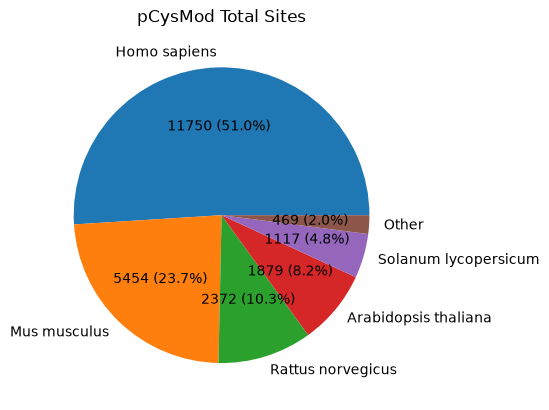

In [117]:
pcys = pd.read_csv("/home/callum/sno_data/processed/pcys/pcys_org.csv")
pcys_unique = pcys[["id", "position", "organism"]].drop_duplicates()

counts = pcys["organism"].value_counts()
print(pcys.shape)


sig = counts[counts > 1000]
sig["Other"] = counts[counts <= 1000].sum()

fig, ax = plt.subplots()
ax.set_title("pCysMod Total Sites")
ax.pie(sig.values, labels=sig.index,
       autopct=lambda p: f'{p * sig.sum() / 100:.0f} ({p:.1f}%)')

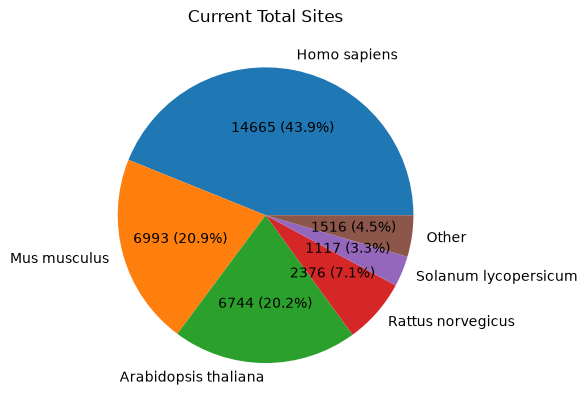

In [111]:
counts = n_unique["organism"].value_counts()

sig = counts[counts > 1000]
sig["Other"] = counts[counts <= 1000].sum()

fig, ax = plt.subplots()

ax.set_title("Current Total Sites")
ax.pie(sig.values, labels=sig.index,
       autopct=lambda p: f'{p * sig.sum() / 100:.0f} ({p:.1f}%)')

In [112]:
# human_only_dfs = {}
# for j, i in dfs.items():
    
#     total = i.shape[0]
#     print(j.upper())
#     print("total number of rows:", total)
    
    
#     mask = i["organism"] == "Homo sapiens"
#     subset = i[mask]
    
    
    
#     out_name = j.replace("_org", "_human") + ".csv"
#     out_dir = path / get_dir(out_name)

#     subset.to_csv(out_dir / out_name, index=False)
    
    
        
#     human_only = subset.shape[0]
#     print("number of human rows:", human_only)
#     print(f"human/total: {human_only}/{total} | {(human_only/total)*100}")
#     print("-------------")

In [113]:
# human_dfs = {}
# #print(dfs)
# for name in dfs:
#     human_name = name.replace("_org", "_human")
#     human_dfs[human_name] = pd.read_csv(path / get_dir(human_name) / f"{human_name}.csv")

# for name, df in human_dfs.items():
#     print(name, df.shape)

In [114]:
# for_comparison = {}

# for dataset, df in human_dfs.items():
#     print(df.columns)
#     for_comparison[dataset] = set(zip(df["id"], df["position"]))

# print(for_comparison)
# # datasets = {
# #     "Dataset A": set(zip(mnat_gsno["id"], mnat_gsno["position"])),

In [115]:
# for dataset, df in human_dfs.items():
#     if not {"id", "position"} <= set(df.columns):
#         print("missing columns:", dataset, list(df.columns))

In [116]:


# datasets = {
#     "Dataset A": set(zip(mnat_gsno["id"], mnat_gsno["position"])),
#     "Dataset B": set(zip(mnat_snap["id"], mnat_snap["position"])),
#     "Dataset C": set(zip(yang["id"], yang["position"])),
#     "Dataset D": set(zip(dn_test["id"], dn_test["position"])),
#     "Dataset E": set(zip(dn_train["id"], dn_train["position"])),

# }